# Reverse Engineering `spike_data.npz`: Simulation and Testing Module

**Author:** Abdulhamit Gökçe (U38891823) · Follow-up to Assignments 2A and 2B ("Finding Spikes in Noisy Neural Data")

This notebook does the whole project in one place:

| Part | What happens | Output files |
|:--|:--|:--|
| **1. Reverse engineering** | Find the spikes, fit a simple model (drift + spikes + noise), check every assumption, simulate a new recording | `simulated_spike_data.npz` (submission), `simulated_spike_data_stochastic.npz`, `model_parameters.json` |
| **2. Testing module** | Write `testing_module.py`, which scores how close any simulation is to the original (0–100) | `testing_module.py` |
| **3. Validation** | Check the scoring rule, make the figures, test the module on deliberately wrong simulations | figures in the notebook |
| **4. Other teams** | Score other teams' files with the same module | ranking table |

### How to run it in Google Colab
1. Open [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook** → choose this `.ipynb` file.
2. Click **Runtime → Run all**.
3. When the upload button appears under *Step 1*, click **Choose Files** and select **`spike_data.npz`**. Everything else runs by itself (about 1–2 minutes).
4. The last cell downloads a ZIP with all result files.

*Tip:* you can also drag `spike_data.npz` into the **Files** panel (folder icon on the left) **before** pressing Run all; then no upload box appears.

All random numbers use fixed seeds, so every number below is reproduced exactly on every run. Only `numpy`, `scipy` and `matplotlib` are needed; Colab already has them.

## Step 0 — Imports

In [1]:
import os
import json
import math
import importlib
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.ndimage import median_filter

plt.rcParams["figure.dpi"] = 110
print("numpy", np.__version__, "| matplotlib", plt.matplotlib.__version__)

numpy 2.5.3 | matplotlib 3.11.2


## Step 1 — Load `spike_data.npz`

If the file is not in the Colab folder yet, an upload box appears. Choose `spike_data.npz`.

In [2]:
DATA_FILE = "spike_data.npz"

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files       # only exists inside Colab
    except ImportError:
        raise FileNotFoundError("Put spike_data.npz in the same folder "
                                "as this notebook and run again.")
    print("Please choose spike_data.npz in the upload box below.")
    uploaded = files.upload()
    if len(uploaded) == 0:
        raise FileNotFoundError("No file was uploaded. Run this cell again.")
    name = list(uploaded.keys())[0]
    if name != DATA_FILE:                     # e.g. "spike_data (1).npz"
        os.replace(name, DATA_FILE)

print("Found", DATA_FILE)

Found spike_data.npz


In [3]:
# Read the two arrays. allow_pickle=False: never run code from a data file.
with np.load(DATA_FILE, allow_pickle=False) as data:
    print("Keys in the file:", data.files)
    t = data["t"]
    x = data["raw_data"]

FS = 1000.0                 # sampling rate (Hz): one sample = 1 ms
N = x.size                  # number of samples
T_REC = N / FS              # recording length (s)

print("t:        shape", t.shape, "dtype", t.dtype)
print("raw_data: shape", x.shape, "dtype", x.dtype)
print("Time step: %.4f s (uniform: %s), duration %.1f s"
      % (np.diff(t).mean(), np.allclose(np.diff(t), 0.001), T_REC))
print("Min %.3f  Max %.3f  Mean %.3f  Median %.3f  SD %.3f  (a.u.)"
      % (x.min(), x.max(), x.mean(), np.median(x), x.std()))

Keys in the file: ['t', 'raw_data']
t:        shape (10000,) dtype float64
raw_data: shape (10000,) dtype float64
Time step: 0.0010 s (uniform: True), duration 10.0 s
Min -1.691  Max 6.202  Mean 0.077  Median 0.035  SD 0.734  (a.u.)


# Part 1 — Reverse engineering

I model every sample $i$ as the sum of three parts:

$$x[i] = b[i] + s[i] + \eta[i], \qquad s[i] = A\sum_{k=1}^{K} w[i-\tau_k], \qquad w[l] = e^{-l/\tau} \ (l \ge 0)$$

* $b$ = slow baseline **drift**
* $s$ = **spikes**: every spike jumps up by $A$ at its onset $\tau_k$ and decays exponentially with time constant $\tau$
* $\eta$ = white Gaussian **noise** with standard deviation $\sigma$

The plan: (1) find the spike onsets $\tau_k$ with the 2B detector, (2) fit drift and amplitude by least squares, (3) the noise is what is left, (4) check each assumption, (5) simulate.

## Step 2 — Spike detection (Assignment 2B detector)

Threshold $= \mu_{\text{local}}[i] + k\,\sigma_{\text{local}}[i]$ with a 500-sample sliding window and $k = 4.5$. A spike is the **first** sample of every run above the threshold.

In [4]:
W = 500      # sliding window (samples)
K = 4.5      # threshold factor


def local_mean_sd(x, w=W):
    # Sliding mean and SD over w samples.
    # The edges are padded by repeating the first/last value.
    padded = np.pad(x, (w // 2, w - 1 - w // 2), mode="edge")
    # Running sums make the sliding mean fast (no Python loop needed).
    c1 = np.concatenate(([0.0], np.cumsum(padded)))
    c2 = np.concatenate(([0.0], np.cumsum(padded ** 2)))
    mean = (c1[w:] - c1[:-w]) / w
    variance = (c2[w:] - c2[:-w]) / w - mean ** 2
    sd = np.sqrt(np.maximum(0.0, variance))
    return mean, sd


def detect_spikes(x, k=K):
    # Index of the first sample of every run above mean + k * SD.
    mean, sd = local_mean_sd(x)
    above = x > mean + k * sd
    starts = above & ~np.r_[False, above[:-1]]   # above now, not before
    return np.flatnonzero(starts)


spike_times = detect_spikes(x)

# The 42 spike indices reported in Assignment 2B
SPIKES_2B = [195, 322, 388, 414, 444, 647, 1421, 1719, 1751, 1855, 2066,
             2312, 2399, 2446, 2481, 2729, 2941, 2996, 3449, 4636, 4652,
             4693, 4756, 5057, 5083, 5331, 5721, 5732, 5873, 5964, 6527,
             6599, 7095, 7130, 7353, 7629, 7980, 8653, 8666, 9408, 9624,
             9793]

print("Spikes found:", len(spike_times),
      "-> firing rate %.2f Hz" % (len(spike_times) / T_REC))
print("Same indices as Assignment 2B:", spike_times.tolist() == SPIKES_2B)
print("Shortest inter-spike interval: %d ms" % np.diff(spike_times).min())

Spikes found: 42 -> firing rate 4.20 Hz
Same indices as Assignment 2B: True
Shortest inter-spike interval: 11 ms


## Step 3 — Fit the model (least squares)

**Drift.** One sine cycle over the recording has its extremes at 2.5 s and 7.5 s. The 2A moving median had them near 2.2 s and 7.9 s. A small downward trend moves a maximum earlier and a minimum later, so:

$$b(t) = a\sin\!\left(\frac{2\pi t}{T_{\text{rec}}}\right) + c\left(t - \frac{T_{\text{rec}}}{2}\right)$$

**Why least squares?** For a fixed decay time $\tau$, the model is *linear* in $a$, $c$ and $A$. So one call of `np.linalg.lstsq` gives the best values. I repeat this for $\tau = 1.0, 1.1, \dots, 8.0$ ms and keep the $\tau$ with the smallest residual. No starting values or optimiser are needed.

In [5]:
KERNEL = 30   # spike kernel length (samples); exp(-29/3) < 1e-4


def spike_train(n, times, tau):
    # Sum of unit-height exponential spikes starting at `times`.
    kernel = np.exp(-np.arange(KERNEL) / tau)
    s = np.zeros(n)
    for i in times:
        m = min(KERNEL, n - i)          # do not run past the end
        s[i:i + m] += kernel[:m]
    return s


def drift_columns(t):
    # The two drift shapes: one sine cycle over T_REC and a straight line.
    return np.column_stack([np.sin(2 * np.pi * t / T_REC), t - T_REC / 2])


# Try every tau on a 0.1 ms grid and keep the best fit
best_rss = None
for tau_try in np.round(np.arange(1.0, 8.01, 0.1), 1):
    X_try = np.column_stack([drift_columns(t),
                             spike_train(N, spike_times, tau_try)])
    coef_try = np.linalg.lstsq(X_try, x, rcond=None)[0]
    rss = float(np.sum((x - X_try @ coef_try) ** 2))
    if best_rss is None or rss < best_rss:
        best_rss, tau, coef, X = rss, float(tau_try), coef_try, X_try

a, c, A = coef
resid = x - X @ coef                          # what the model leaves over
sigma = math.sqrt(best_rss / (N - 4))         # 4 fitted values: a, c, A, tau
se = sigma * np.sqrt(np.diag(np.linalg.inv(X.T @ X)))   # standard errors

print("Drift: b(t) = %.3f sin(2 pi t / 10 s) %+.4f (t - 5 s)" % (a, c))
print("       standard errors: a %.3f, c %.4f" % (se[0], se[1]))
print("Spike: A = %.3f +- %.3f a.u., tau = %.1f ms" % (A, se[2], tau))
print("Noise: sigma = %.4f a.u.  ->  A / sigma = %.1f" % (sigma, A / sigma))

drift = drift_columns(t) @ [a, c]
print("Fitted drift: max %+.3f at %.2f s, min %+.3f at %.2f s"
      % (drift.max(), t[drift.argmax()], drift.min(), t[drift.argmin()]))

Drift: b(t) = 0.535 sin(2 pi t / 10 s) -0.0418 (t - 5 s)
       standard errors: a 0.007, c 0.0017
Spike: A = 5.012 +- 0.032 a.u., tau = 3.0 ms
Noise: sigma = 0.2985 a.u.  ->  A / sigma = 16.8
Fitted drift: max +0.644 at 2.30 s, min -0.644 at 7.70 s


## Step 4 — Check every assumption

Each assumption is compared with a simple alternative or with what noise alone would produce.

### 4a. Drift shape: Bayesian Information Criterion

$\text{BIC} = N\ln(\text{RSS}/N) + k\ln N$, where $k$ counts all fitted parameters. Lower is better; one extra parameter costs $\ln N \approx 9.2$.

In [6]:
spikes_unit = spike_train(N, spike_times, tau)
sine = np.sin(2 * np.pi * t / T_REC)
line = t - T_REC / 2


def bic(columns, k):
    # Fit drift columns + spike train, return the BIC.
    X_b = np.column_stack(columns + [spikes_unit])
    rss_b = np.sum((x - X_b @ np.linalg.lstsq(X_b, x, rcond=None)[0]) ** 2)
    return round(float(N * np.log(rss_b / N) + k * np.log(N)), 1)


# Free-frequency sine: search the frequency on a fine grid
best_free = None
for f in np.arange(0.05, 0.2, 0.0005):
    value = bic([np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t)], 5)
    if best_free is None or value < best_free[0]:
        best_free = (value, round(float(f), 4))

bic_table = {
    "0.1 Hz sine (k=3)": bic([sine], 3),
    "0.1 Hz sine + trend (k=4, CHOSEN)": bic([sine, line], 4),
    "0.1 Hz sine + phase + offset + trend (k=6)":
        bic([sine, np.cos(2 * np.pi * t / T_REC), np.ones(N), line], 6),
    "free-frequency sine (%.3f Hz) with phase (k=5)" % best_free[1]:
        best_free[0],
}
for name, value in bic_table.items():
    print("%-48s BIC %10.1f" % (name, value))

0.1 Hz sine (k=3)                                BIC   -23535.7
0.1 Hz sine + trend (k=4, CHOSEN)                BIC   -24146.5
0.1 Hz sine + phase + offset + trend (k=6)       BIC   -24129.0
free-frequency sine (0.091 Hz) with phase (k=5)  BIC   -24137.0


### 4b. One amplitude for all spikes? Is the decay exponential? Are the tail "rebounds" real?

* If every spike gets its own amplitude, the spread of these amplitudes should be about $\sigma/\lVert w\rVert$ when the spikes are really identical.
* The empirical template is $\bar w[l] = \sum_k y[\tau_k+l] \,/\, \sum_k y[\tau_k]$ with $y = x - \hat b$.
* A rise from lag $l-1$ to $l$ happens by chance with probability $p_l = \Phi\!\left(A(w[l]-w[l-1]) / (\sqrt2\,\sigma)\right)$.

In [7]:
# One amplitude per spike (drift fitted jointly)
X_each = np.column_stack([drift_columns(t)] +
                         [spike_train(N, [i], tau) for i in spike_times])
amps = np.linalg.lstsq(X_each, x, rcond=None)[0][2:]
w_kernel = np.exp(-np.arange(KERNEL) / tau)
amp_sd = float(amps.std(ddof=1))
amp_sd_noise = sigma / float(np.linalg.norm(w_kernel))
print("Per-spike amplitudes: %.2f to %.2f a.u., SD %.3f" %
      (amps.min(), amps.max(), amp_sd))
print("SD expected from noise alone:          %.3f  -> same, so one A is enough"
      % amp_sd_noise)

# Empirical template on lags 0..8 ms (drift removed, normalised to lag 0)
y = x - drift
segments = np.array([y[i:i + 9] for i in spike_times if i + 9 <= N])
template = segments.sum(axis=0) / segments[:, 0].sum()
print("\nLag (ms)       ", " ".join("%6d" % l for l in range(9)))
print("Template       ", " ".join("%6.3f" % v for v in template))
print("exp(-l/%.1f)   " % tau,
      " ".join("%6.3f" % np.exp(-l / tau) for l in range(9)))
print("Largest difference: %.3f" %
      np.abs(template - np.exp(-np.arange(9) / tau)).max())

# Tail rises: observed versus expected by chance
print("\nTail rises (lag l-1 -> l):")
tail_rises = {}
for lag in (2, 3, 4):
    z = A * (w_kernel[lag] - w_kernel[lag - 1]) / (math.sqrt(2) * sigma)
    chance = 0.5 * (1 + math.erf(z / math.sqrt(2)))       # Phi(z)
    observed = int(np.sum(segments[:, lag] > segments[:, lag - 1]))
    expected = len(segments) * chance
    tail_rises["+%d ms" % lag] = {"observed": observed,
                                  "expected": round(expected, 2)}
    print("  +%d ms: observed %d, expected by chance %.2f"
          % (lag, observed, expected))

Per-spike amplitudes: 4.59 to 5.41 a.u., SD 0.205
SD expected from noise alone:          0.208  -> same, so one A is enough

Lag (ms)             0      1      2      3      4      5      6      7      8
Template         1.000  0.709  0.510  0.383  0.246  0.192  0.131  0.096  0.070
exp(-l/3.0)     1.000  0.717  0.513  0.368  0.264  0.189  0.135  0.097  0.069
Largest difference: 0.018

Tail rises (lag l-1 -> l):
  +2 ms: observed 2, expected by chance 0.33
  +3 ms: observed 3, expected by chance 1.76
  +4 ms: observed 2, expected by chance 4.53


### 4c. Is the residual noise white and Gaussian? Is sample 1014 an outlier?

For Gaussian noise, skewness and excess kurtosis are 0. For white noise the lag-1 autocorrelation is 0 (standard error $1/\sqrt N = 0.01$). The largest of $N$ Gaussian samples reaches $|z|$ with probability $1-\text{erf}(|z|/\sqrt2)^N$.

In [8]:
z_scores = (resid - resid.mean()) / resid.std()
z_max = float(np.abs(z_scores).max())
noise_check = {
    "skewness": float(np.mean(z_scores ** 3)),
    "excess_kurtosis": float(np.mean(z_scores ** 4) - 3),
    "lag1_r": float(np.corrcoef(resid[1:], resid[:-1])[0, 1]),
    "largest_abs_z": z_max,
    "at_sample": int(np.abs(z_scores).argmax()),
    "p_largest": 1 - math.erf(z_max / math.sqrt(2)) ** N,
}
for key, value in noise_check.items():
    print("%-16s %.4f" % (key, value) if isinstance(value, float)
          else "%-16s %d" % (key, value))

# The same 2B estimator (x - local mean, spike windows removed) on the data
mean_loc, _ = local_mean_sd(x)
keep = np.ones(N, dtype=bool)
for i in spike_times:
    keep[max(0, i - 2):i + 8] = False
print("\n2B-style noise SD (x - local mean, [-2,+7] ms removed): %.3f a.u."
      % (x - mean_loc)[keep].std())
print("Generator noise SD sigma:                               %.4f a.u."
      % sigma)

skewness         0.0209
excess_kurtosis  -0.0435
lag1_r           -0.0195
largest_abs_z    4.3171
at_sample        1014
p_largest        0.1463

2B-style noise SD (x - local mean, [-2,+7] ms removed): 0.303 a.u.
Generator noise SD sigma:                               0.2985 a.u.


### 4d. Spike train: Poisson-like?

A Poisson process gives an inter-spike-interval coefficient of variation (CV) of 1 and a count variance/mean ratio (dispersion) of 1.

In [9]:
isi = np.diff(spike_times)
counts = np.bincount(spike_times // int(FS), minlength=int(T_REC))
dispersion = float(counts.var(ddof=1) / counts.mean())
chi2_p = float(stats.chi2.sf(dispersion * (len(counts) - 1), len(counts) - 1))
train_check = {"min_isi_ms": int(isi.min()),
               "isi_cv": float(isi.std() / isi.mean()),
               "counts_per_s": counts.tolist(),
               "dispersion": dispersion}
print("Spikes per second:", counts.tolist())
print("Dispersion %.2f (chi2 test p = %.2f), ISI CV %.2f, shortest ISI %d ms"
      % (dispersion, chi2_p, train_check["isi_cv"], isi.min()))

Spikes per second: [6, 4, 8, 1, 4, 7, 2, 5, 2, 3]
Dispersion 1.26 (chi2 test p = 0.25), ISI CV 1.07, shortest ISI 11 ms


## Step 5 — Simulate and save the results file

* **Deterministic mode (submission, seed 2026):** same 42 spike onsets, fitted drift, fitted spike shape, **new** Gaussian noise.
* **Stochastic mode (seed 2027):** identical, but 42 **new random** onsets. I draw 42 distinct samples uniformly and redraw until no interval is shorter than the 6 ms dead time. For a fixed spike count this is a Poisson process with dead time.

Both files are saved exactly like the original: keys `t` and `raw_data`, `float64`, shape `(10000,)`. The time axis is copied from the original, so it is bit-identical.

In [10]:
DEAD_TIME = 6     # shortest allowed interval in the stochastic mode (ms)


def random_spike_times(n, k, rng):
    # k uniform onsets, redrawn until no interval is shorter than DEAD_TIME.
    while True:
        times = np.sort(rng.choice(n, size=k, replace=False))
        if np.all(np.diff(times) >= DEAD_TIME):
            return times


def simulate(mode, seed):
    # Drift + spikes + new Gaussian noise.
    rng = np.random.default_rng(seed)
    times = spike_times
    if mode == "stochastic":
        times = random_spike_times(N, len(spike_times), rng)
    spikes = A * spike_train(N, times, tau)
    return drift + spikes + rng.normal(0.0, sigma, N)


def save_like_original(path, x_new):
    # Save with the same structure as spike_data.npz, then check the file.
    np.savez(path, t=t, raw_data=x_new)
    with np.load(path, allow_pickle=False) as f:
        ok = (sorted(f.files) == ["raw_data", "t"]
              and all(f[key].dtype == np.float64 and f[key].shape == (N,)
                      and np.all(np.isfinite(f[key])) for key in f.files)
              and np.array_equal(f["t"], t))
    if not ok:
        raise ValueError(path + " does not have the original structure")
    print("Saved", path, "- structure OK")


x_det = simulate("deterministic", seed=2026)
x_sto = simulate("stochastic", seed=2027)
save_like_original("simulated_spike_data.npz", x_det)
save_like_original("simulated_spike_data_stochastic.npz", x_sto)

# Save all parameters and checks (for the report)
params = {"a": float(a), "a_se": float(se[0]), "c": float(c),
          "c_se": float(se[1]), "A": float(A), "A_se": float(se[2]),
          "tau_ms": tau, "sigma": sigma, "spike_times": spike_times.tolist()}
checks = {"bic": bic_table,
          "amplitudes": {"sd": amp_sd, "sd_noise_only": amp_sd_noise},
          "template": template.round(3).tolist(), "tail_rises": tail_rises,
          "noise": noise_check, "spike_train": train_check}
with open("model_parameters.json", "w") as f:
    json.dump({"parameters": params, "checks": checks}, f, indent=1)
print("Saved model_parameters.json")

# Table 1: global statistics
print("\n%-14s %8s %8s %8s %8s %8s %7s" %
      ("File", "Min", "Max", "Mean", "Median", "SD", "Spikes"))
for name, sig in [("Original", x), ("Deterministic", x_det),
                  ("Stochastic", x_sto)]:
    print("%-14s %8.3f %8.3f %8.3f %8.3f %8.3f %7d" %
          (name, sig.min(), sig.max(), sig.mean(), np.median(sig),
           sig.std(), len(detect_spikes(sig))))

Saved simulated_spike_data.npz - structure OK
Saved simulated_spike_data_stochastic.npz - structure OK
Saved model_parameters.json

File                Min      Max     Mean   Median       SD  Spikes
Original         -1.691    6.202    0.077    0.035    0.734      42
Deterministic    -1.788    6.082    0.074    0.036    0.731      42
Stochastic       -1.637    6.081    0.077    0.047    0.718      42


# Part 2 — Testing module (`testing_module.py`)

The teacher will use the teams' testing modules to rank the simulations, so the module must (1) reward a correct model, (2) give the same number for the same file, and (3) be hard to game.

### Why RMSE alone is not enough
Write the original as $x = D + \eta$ and a candidate as $\hat x = \hat D + \hat\eta$ (independent noises with SD $\sigma$, $\sigma_c$):

$$\mathbb E[\text{RMSE}^2] = \tfrac1N\textstyle\sum_i (\hat D[i]-D[i])^2 + \sigma_c^2 + \sigma^2$$

* A **perfect** generator still gets RMSE $=\sqrt2\,\sigma \approx 0.42$.
* A **noise-free** curve gets a *better* RMSE ($\sigma \approx 0.30$) although its noise and spectrum are wrong.
* A correct model with **new spike times** gets $\approx 0.78$ although all its statistics are right.

So the module measures 10 simple properties in four tiers, and judges each error against the error that **chance alone** produces.

### Scoring rule
For every metric $m$ with error $e_m$ (0 = identical) and tolerance $\epsilon_m$ (95th percentile of the error between two runs of a perfect generator):

$$s_m = \min\!\left(1, \frac{\epsilon_m}{e_m}\right), \qquad S = 100\cdot\frac14\sum_{\text{tiers}} \overline{s}_{\text{tier}}$$

Chance-level error → full marks; twice the chance level → 0.5. No hand-tuned weights.

| Tier | Metric | Error (0 = identical) | Tolerance |
|:--|:--|:--|:--:|
| T1 Signal & drift | `rmse` | RMSE of the two signals | 0.43 |
| | `drift_rmse` | RMSE of the 501-sample moving medians | 0.035 |
| T2 Noise | `noise_sd` | relative error of the residual-noise SD | 0.027 |
| | `noise_ks` | KS distance of the residual-noise values | 0.021 |
| T3 Spectrum | `drift_band` | \|log2\| Welch power ratio, 0–5 Hz | 0.21 |
| | `band_profile` | mean \|log2\| power ratio, 7 octave bands 5–500 Hz | 0.19 |
| T4 Spikes | `firing_rate` | \|Δ rate\| (Hz) | 0.1 |
| | `waveform_rmse` | RMSE of the mean waveforms, 0 to +7 ms | 0.12 |
| | `spike_times` | 1 − F1, spikes match within ±2 ms | 0.023 |
| | `isi_ks` | KS distance of the inter-spike intervals | 0.22 |

**T0 (loading and structure):** the strict check (keys exactly `t` and `raw_data`, `float64`, shape `(10000,)`, no NaN/Inf, `t` equal to the original) is always reported. Other teams' files often differ (missing `t`, other key names such as `data` or `arr_0`, `float32`, shape `(1, 10000)`, `.npy`/`.csv` files, a few NaNs), so the loader repairs what it can without touching the signal values and lists every repair. A repaired file is scored, but its composite is multiplied by 0.9; with `--strict` any failed check gives 0. Only files without a usable 10 000-sample signal get 0. Files are read with `allow_pickle=False`, and one broken file never stops the ranking.
**Copy check:** the correlation between the candidate's and the original's residual noise; above 0.3 the file is flagged as "copied?".
**Statistics-only score:** the same score without the two time-locked metrics (`rmse`, `spike_times`).

The next cell writes the module to a real file, so it can be shared with the class and run as `python testing_module.py candidate.npz`. It is standalone, so it contains its own copy of the 2B detector.

In [11]:
%%writefile testing_module.py
"""Testing module: how close is a simulation to spike_data.npz?

Reverse Engineering Project, Part 2 (follow-up to Assignments 2A and 2B).
Author: Abdulhamit Gokce.

What it does
    1. Loading (T0): the candidate file is read without pickled objects.
       Files from other teams often differ from spike_data.npz (missing
       ``t``, other key names, float32, shape (1, 10000), .npy/.csv
       instead of .npz, a few NaNs). The loader repairs what can be
       repaired without guessing the signal itself and records every
       repair. Only files with no usable 10000-sample signal get 0.
    2. Structure check: the strict comparison with spike_data.npz (keys
       exactly t and raw_data, float64, shape (10000,), no NaN/Inf, t equal
       to the original) is still reported. A file that needed repairs is
       scored, but its composite is reduced by SCHEMA_PENALTY (10 %).
       With --strict the old rule applies: any failed check -> 0.
    3. Measures 10 properties in the candidate and in the original.
    4. Turns every difference (error e, 0 = identical) into a score with
       one rule:   score = min(1, tolerance / e)
       tolerance = the error that two runs of a perfect generator show by
       chance (95th percentile, calibrated in validate_and_plot.py).
       Chance-level error -> 1, twice the chance level -> 0.5.
    5. Tier score = mean of its metric scores;
       composite  = 100 * mean of the four tier scores.

Usage
    python testing_module.py candidate.npz [more.npz ...]
    python testing_module.py teams_folder/            # every file inside
    python testing_module.py candidate.npz --reference path/spike_data.npz
    python testing_module.py teams_folder/ --csv ranking.csv
    python testing_module.py candidate.npz --strict   # no repairs allowed

    from testing_module import evaluate
    print(evaluate("candidate.npz")["composite"])

Requirements: numpy, scipy. No random numbers: same file -> same score.
One unreadable file never stops the ranking of the others.
"""
import argparse
import csv
import glob
import os

import numpy as np
from scipy import signal, stats
from scipy.ndimage import median_filter

FS = 1000.0              # sampling rate (Hz): 1 sample = 1 ms
N = 10_000               # samples in spike_data.npz
W, K = 500, 4.5          # Assignment 2B detector: window, threshold factor
MASK = (2, 7)            # noise: drop samples [-2, +7] ms around each spike
WAVE = np.arange(8)      # mean spike waveform on lags [0, +7] ms
MEDIAN = 501             # Assignment 2A moving-median baseline (samples)
BANDS = (0, 5, 10, 20, 40, 80, 160, 320, 501)   # Hz; [0, 5) = drift band
MATCH = 2                # two spikes match if at most 2 ms apart
COPY_LIMIT = 0.3         # noise correlation above this = copied noise
SCHEMA_PENALTY = 0.10    # composite x 0.9 if the file needed repairs
MAX_NAN_FRACTION = 0.01  # up to 1 % NaN/Inf samples are interpolated
EXTENSIONS = (".npz", ".npy", ".csv", ".txt", ".mat")

# accepted names (lower case, without spaces, dashes or dots)
SIGNAL_KEYS = ("raw_data", "rawdata", "raw", "data", "signal", "sig",
               "x", "y", "v", "voltage", "trace", "recording", "lfp",
               "sim", "simulation", "simulated", "simulated_data",
               "sim_data", "simulated_raw_data", "raw_data_sim",
               "x_sim", "output")
TIME_KEYS = ("t", "time", "times", "timestamp", "timestamps", "time_s",
             "t_s", "tt", "ts", "time_ms", "t_ms")

# metric: (tier, tolerance, description)
METRICS = {
    "rmse": ("T1", 0.43, "RMSE of the two signals (a.u.)"),
    "drift_rmse": ("T1", 0.035, "RMSE of the moving medians (a.u.)"),
    "noise_sd": ("T2", 0.027, "relative error of the noise SD"),
    "noise_ks": ("T2", 0.021, "KS distance of the noise values"),
    "drift_band": ("T3", 0.21, "|log2| power ratio, 0-5 Hz"),
    "band_profile": ("T3", 0.19, "mean |log2| power ratio, 5-500 Hz"),
    "firing_rate": ("T4", 0.1, "firing-rate difference (Hz)"),
    "waveform_rmse": ("T4", 0.12, "RMSE of the mean waveforms (a.u.)"),
    "spike_times": ("T4", 0.023, "1 - F1 of spike times (+-2 ms)"),
    "isi_ks": ("T4", 0.22, "KS distance of the intervals"),
}
TIERS = {"T1": "Signal and drift", "T2": "Noise", "T3": "Spectrum",
         "T4": "Spikes"}
# compared at the same moments -> need the original spike times;
# left out of the "statistics-only" score
TIME_LOCKED = ("rmse", "spike_times")


class UnusableFile(Exception):
    """The file holds no signal that can be compared with the original."""


# ----------------------------------------------------------------------------
# Assignment 2B detector
# What: threshold = sliding mean + k * sliding SD (W = 500 samples); a spike
#       is the first sample of every run above the threshold.
# Why:  every team knows it, so all files are measured the same way. The
#       spikes are ~17 noise SDs high and >= 11 ms apart, so a more
#       elaborate detector would find the same 42 spikes.
# ----------------------------------------------------------------------------
def local_mean_sd(x, w=W):
    """Sliding mean and SD over w samples (cumulative sums, edge padding)."""
    padded = np.pad(x, (w // 2, w - 1 - w // 2), mode="edge")
    c1 = np.concatenate(([0.0], np.cumsum(padded)))
    c2 = np.concatenate(([0.0], np.cumsum(padded ** 2)))
    mean = (c1[w:] - c1[:-w]) / w
    sd = np.sqrt(np.maximum(0.0, (c2[w:] - c2[:-w]) / w - mean ** 2))
    return mean, sd


def detect_spikes(x, k=K):
    """Sample index of the first sample of every run above mean + k * SD."""
    mean, sd = local_mean_sd(x)
    above = x > mean + k * sd
    return np.flatnonzero(above & ~np.r_[False, above[:-1]])


# ----------------------------------------------------------------------------
# T0: reading and repairing other teams' files
# What: read the file (never unpickle), find the signal and the time
#       array, and repair the shape, dtype and missing values.
# Why:  the module ranks every team. A team with a good simulation but
#       a missing ``t`` array or a key called "data" must not crash the
#       ranking or be reported as a 0 without explanation. Repairs never
#       change the signal values, except interpolating a few NaNs.
# ----------------------------------------------------------------------------
def _norm(name):
    return name.lower().replace(" ", "").replace("-", "_").replace(".", "_")


def read_arrays(path):
    """All numeric arrays in a file, as {name: ndarray}."""
    ext = os.path.splitext(path)[1].lower()
    if ext == ".npy":
        return {"arr_0": np.load(path, allow_pickle=False)}
    if ext in (".csv", ".txt"):
        table = np.genfromtxt(path, delimiter="," if ext == ".csv" else None,
                              names=None, comments="#")
        if table.ndim == 2 and np.all(np.isnan(table[0])):
            table = table[1:]                    # header row
        return {"arr_0": table}
    if ext == ".mat":
        from scipy.io import loadmat
        mat = loadmat(path)
        return {k: v for k, v in mat.items() if not k.startswith("__")}
    with np.load(path, allow_pickle=False) as data:   # .npz (or no ext)
        return {key: data[key] for key in data.files}


def _columns(name, a):
    """Split one array into named 1D candidates."""
    a = np.asarray(a)
    if a.dtype.kind not in "biuf":
        return {}
    a = np.squeeze(a)
    if a.ndim == 1:
        return {name: a}
    if a.ndim == 2 and min(a.shape) <= 4:        # (2, N), (N, 2), ...
        cols = a if a.shape[0] <= 4 else a.T
        return {f"{name}[{j}]": c for j, c in enumerate(cols)}
    return {}


def _is_time(a):
    """Monotonic array with a constant step (looks like timestamps)."""
    if a.size < 3 or not np.all(np.isfinite(a)):
        return False
    d = np.diff(a.astype(np.float64))
    return bool(d.min() > 0 and np.allclose(d, d[0], rtol=1e-3))


def _pick(cands, keys):
    lookup = {_norm(n.split("[")[0]): n for n in cands}
    for key in keys:
        if key in lookup:
            return lookup[key]
    return None


def load_candidate(path):
    """Return (t, x, repairs, raw) for any reasonable candidate file.

    t, x: float64 arrays of shape (N,); repairs: list of strings;
    raw: the arrays as stored in the file (for the strict check).
    Raises UnusableFile if no comparable signal is found.
    """
    try:
        raw = read_arrays(path)
    except Exception as err:            # noqa: BLE001 (other teams' files)
        text = str(err)
        if "pickle" in text.lower():
            text = ("not a valid .npz/.npy file, or it stores Python "
                    "objects instead of numeric arrays (save with "
                    "np.savez(path, t=t, raw_data=x))")
        raise UnusableFile(f"cannot read the file: {text}") from err
    if not raw:
        raise UnusableFile("the file contains no arrays")

    cands = {}
    for name, a in raw.items():
        cands.update(_columns(name, a))
    if not cands:
        raise UnusableFile("no numeric 1D array in the file "
                           f"(keys: {sorted(raw)})")
    repairs = []

    # signal: a known name first, else the longest non-time array
    sig_name = _pick(cands, SIGNAL_KEYS)
    if sig_name is not None and _is_time(cands[sig_name]) \
            and _norm(sig_name.split("[")[0]) not in ("raw_data", "signal"):
        sig_name = None
    if sig_name is None:
        others = [n for n in cands if not _is_time(cands[n])]
        if not others:
            raise UnusableFile("only time-like arrays found "
                               f"(keys: {sorted(raw)})")
        sig_name = max(others, key=lambda n: (cands[n].size == N,
                                              cands[n].size))
    if sig_name != "raw_data":
        repairs.append(f"signal read from '{sig_name}' (not 'raw_data')")
    x = cands.pop(sig_name)
    stored = np.shape(raw.get(sig_name, x))
    if "[" not in sig_name and stored != x.shape:
        repairs.append(f"signal shape {stored} flattened to {x.shape}")

    # time: a known name first, else any timestamp-like array
    t_name = _pick(cands, TIME_KEYS)
    if t_name is None:
        times = [n for n in cands if _is_time(cands[n])]
        t_name = times[0] if times else None
    t = None if t_name is None else cands[t_name]
    if t is None:
        repairs.append("'t' missing: rebuilt as arange(N) / 1000 s")
    elif t_name != "t":
        repairs.append(f"time read from '{t_name}' (not 't')")

    # dtype
    if x.dtype != np.float64:
        repairs.append(f"raw_data cast from {x.dtype} to float64")
    x = x.astype(np.float64)

    # length
    if x.size < N:
        raise UnusableFile(f"signal has {x.size} samples, {N} are needed")
    if x.size > N:
        repairs.append(f"signal truncated from {x.size} to {N} samples")
        x = x[:N]

    # NaN / Inf
    bad = ~np.isfinite(x)
    if bad.any():
        if bad.mean() > MAX_NAN_FRACTION:
            raise UnusableFile(f"{bad.sum()} NaN/Inf samples "
                               f"(> {MAX_NAN_FRACTION:.0%})")
        idx = np.arange(N)
        x[bad] = np.interp(idx[bad], idx[~bad], x[~bad])
        repairs.append(f"{bad.sum()} NaN/Inf samples interpolated")

    # time array: units and length (scoring is by sample index anyway)
    if t is not None:
        t = t.astype(np.float64)
        if t.size >= N and _is_time(t[:N]):
            step = float(np.median(np.diff(t[:N])))
            if np.isclose(step, 1.0, rtol=1e-3):
                repairs.append("t was in ms: converted to s")
                t = t / 1000.0
            elif not np.isclose(step, 1.0 / FS, rtol=1e-3):
                repairs.append(f"t has step {step:g} (not 1 ms): "
                               "rebuilt as arange(N) / 1000 s")
                t = None
        else:
            repairs.append("t unusable (length or not uniform): rebuilt")
            t = None
    t = np.arange(N) / FS if t is None else t[:N]
    return t, x, repairs, raw


def check_structure(data, t_ref):
    """Strict comparison with spike_data.npz: list of (check, passed)."""
    checks = [("keys are exactly t and raw_data",
               sorted(data) == ["raw_data", "t"])]
    for key in ("t", "raw_data"):
        if key not in data:
            checks.append((f"{key}: present", False))
            continue
        a = np.asarray(data[key])
        numeric = a.dtype.kind in "biuf"
        checks += [(f"{key}: shape (10000,)", a.shape == (N,)),
                   (f"{key}: dtype float64", a.dtype == np.float64),
                   (f"{key}: no NaN or Inf",
                    numeric and bool(np.all(np.isfinite(a))))]
    t = np.asarray(data.get("t", np.empty(0)))
    checks.append(("t equal to the original (dt = 1 ms)",
                   t.shape == t_ref.shape and t.dtype == np.float64
                   and np.allclose(t, t_ref, rtol=0, atol=1e-9)))
    return checks


def load(path):
    """Arrays of an .npz file (kept for backward compatibility)."""
    return read_arrays(path)


# ----------------------------------------------------------------------------
# Features and errors
# What: the same properties are measured in both signals: spikes (2B),
#       residual noise (signal - local mean, spike windows removed), the 2A
#       moving-median drift, band powers of the Welch spectrum and the mean
#       spike waveform. Each metric is one simple formula on these.
# Why:  each tier answers one question. T1: is the signal (and its drift)
#       in the right place? T2: is the noise the right size and shape?
#       T3: is the power at slow and fast frequencies right? T4: are the
#       spikes right (how many, which shape, when, how spaced)?
# ----------------------------------------------------------------------------
def features(x):
    """All properties of one signal."""
    n = x.size
    mean, _ = local_mean_sd(x)
    spikes = detect_spikes(x)
    keep = np.ones(n, dtype=bool)
    for i in spikes:
        keep[max(0, i - MASK[0]):i + MASK[1] + 1] = False
    resid = x - mean                                  # 2B residual
    freqs, psd = signal.welch(x - x.mean(), fs=FS, nperseg=1024,
                              detrend=False)
    bands = np.array([psd[(freqs >= lo) & (freqs < hi)].sum()
                      for lo, hi in zip(BANDS[:-1], BANDS[1:])])
    starts = spikes[spikes + WAVE[-1] < n]
    return {"x": x, "spikes": spikes, "keep": keep, "resid": resid,
            "noise": resid[keep], "bands": bands,
            "drift": median_filter(x, size=MEDIAN, mode="nearest"),
            "waves": resid[starts[:, None] + WAVE]}


def rms(d):
    return float(np.sqrt(np.mean(d ** 2)))


def ks(a, b):
    """Largest gap between two empirical CDFs (nan if a sample is empty)."""
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    return float(stats.ks_2samp(a, b, method="asymp").statistic)


def f1(a, b):
    """F1 of two spike trains; a pair matches if at most MATCH ms apart."""
    if len(a) + len(b) == 0:
        return 1.0
    free = np.ones(len(b), dtype=bool)
    hits = 0
    for time in a:
        dist = np.where(free, np.abs(b - time), MATCH + 1)
        if len(dist) and dist.min() <= MATCH:
            free[dist.argmin()] = False
            hits += 1
    return 2 * hits / (len(a) + len(b))


def mean_wave(f):
    return f["waves"].mean(axis=0) if len(f["waves"]) else np.nan


def errors(ref, cand):
    """Error of every metric: 0 = identical, larger = worse."""
    inner = slice(MEDIAN // 2, -(MEDIAN // 2))   # median is biased at ends
    duration = ref["x"].size / FS                # s
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.abs(np.log2(cand["bands"] / ref["bands"]))
        sd_err = abs(cand["noise"].std() / ref["noise"].std() - 1) \
            if cand["noise"].size else float("nan")
    return {
        "rmse": rms(cand["x"] - ref["x"]),
        "drift_rmse": rms(cand["drift"][inner] - ref["drift"][inner]),
        "noise_sd": float(sd_err),
        "noise_ks": ks(cand["noise"], ref["noise"]),
        "drift_band": float(ratio[0]),
        "band_profile": float(ratio[1:].mean()),
        "firing_rate": abs(len(cand["spikes"]) - len(ref["spikes"]))
        / duration,
        "waveform_rmse": rms(mean_wave(cand) - mean_wave(ref)),
        "spike_times": 1 - f1(cand["spikes"], ref["spikes"]),
        "isi_ks": ks(np.diff(cand["spikes"]), np.diff(ref["spikes"])),
    }


# ----------------------------------------------------------------------------
# Scores
# What: error -> score with min(1, tolerance / error), then means.
# Why:  one rule for every metric, no hand-tuned weights, and an error that
#       a perfect simulation could also show is never punished.
# ----------------------------------------------------------------------------
def score(error, tolerance):
    if not np.isfinite(error):          # e.g. no spikes detected
        return 0.0
    return 1.0 if error <= tolerance else tolerance / error


def composite(scores, skip=()):
    """100 * mean over tiers of the mean metric score in each tier."""
    tiers = {tier: float(np.mean([s for m, s in scores.items()
                                  if METRICS[m][0] == tier
                                  and m not in skip]))
             for tier in TIERS}
    return 100 * float(np.mean(list(tiers.values()))), tiers


def compare(ref, x):
    """Errors, scores and composite of signal x against features ref."""
    cand = features(x)
    err = errors(ref, cand)
    scores = {m: score(err[m], METRICS[m][1]) for m in METRICS}
    total, tiers = composite(scores)
    stats_only, _ = composite(scores, skip=TIME_LOCKED)
    # copy check: correlation of the two noise traces outside all spikes
    both = ref["keep"] & cand["keep"]
    with np.errstate(divide="ignore", invalid="ignore"):
        noise_r = float(np.corrcoef(ref["resid"][both],
                                    cand["resid"][both])[0, 1])
    return {"errors": err, "scores": scores, "tiers": tiers,
            "composite": total, "statistics_only": stats_only,
            "noise_r": noise_r, "n_spikes": len(cand["spikes"])}


def evaluate(path, reference="spike_data.npz", ref=None, strict=False):
    """Full evaluation of one candidate file (dict; composite 0-100).

    Never raises for a bad candidate: problems end up in report["notes"].
    """
    original = load_candidate(reference)
    t_ref = original[0]
    if ref is None:
        ref = features(original[1])
    report = {"checks": [], "repairs": [], "composite": 0.0,
              "statistics_only": 0.0, "unpenalised": 0.0, "notes": []}
    try:
        _, x, repairs, raw = load_candidate(path)
    except UnusableFile as err:
        report["notes"].append(f"unusable file: {err}; score 0")
        return report
    report["checks"] = check_structure(raw, t_ref)
    report["repairs"] = repairs
    compliant = all(ok for _, ok in report["checks"])
    if strict and not compliant:
        report["notes"].append("structure check failed (--strict): score 0")
        return report
    try:
        report.update(compare(ref, x))
    except Exception as err:            # noqa: BLE001 (never stop a ranking)
        report["notes"].append(f"evaluation failed ({err}); score 0")
        return report
    report["unpenalised"] = report["composite"]
    if not compliant:
        factor = 1.0 - SCHEMA_PENALTY
        report["composite"] *= factor
        report["statistics_only"] *= factor
        report["notes"].append(f"structure differs from spike_data.npz: "
                               f"score x {factor:.2f} after repairs")
    if report["noise_r"] > COPY_LIMIT:
        report["notes"].append(f"noise correlates with the original noise "
                               f"(r = {report['noise_r']:.2f}): copied?")
    return report


# ----------------------------------------------------------------------------
# Command line
# ----------------------------------------------------------------------------
def show(name, rep):
    print(f"=== {name} ===")
    for check, ok in rep["checks"]:
        print(f"  [{'PASS' if ok else 'FAIL'}] {check}")
    for repair in rep["repairs"]:
        print(f"  [FIX ] {repair}")
    for tier, title in TIERS.items():
        if "tiers" not in rep:
            break
        print(f"{tier} {title}: {100 * rep['tiers'][tier]:.1f}")
        for m, (metric_tier, tol, text) in METRICS.items():
            if metric_tier == tier:
                print(f"    {m:<14} {text:<36} error "
                      f"{rep['errors'][m]:8.4f}  tol {tol:<6} "
                      f"score {rep['scores'][m]:.2f}")
    if "tiers" in rep:
        print(f"Spikes found: {rep['n_spikes']}; noise correlation with "
              f"the original: {rep['noise_r']:.3f}")
    print(f"Statistics-only score: {rep['statistics_only']:.1f}")
    print(f"COMPOSITE SCORE: {rep['composite']:.1f} / 100")
    for note in rep["notes"]:
        print(f"  NOTE: {note}")
    print()


def expand(paths, reference):
    """Files to score: folders are expanded, the reference is skipped."""
    files = []
    for p in paths:
        if os.path.isdir(p):
            found = sorted(f for f in glob.glob(os.path.join(p, "*"))
                           if f.lower().endswith(EXTENSIONS))
            files += found
        else:
            files.append(p)
    ref_abs = os.path.abspath(reference)
    return [f for f in files if os.path.abspath(f) != ref_abs]


def main():
    parser = argparse.ArgumentParser(description="Score simulations of "
                                     "spike_data.npz from 0 to 100.")
    parser.add_argument("candidates", nargs="+",
                        help="files (.npz/.npy/.csv/.txt/.mat) or folders")
    parser.add_argument("--reference", default="spike_data.npz")
    parser.add_argument("--strict", action="store_true",
                        help="score 0 for any file that differs in "
                        "structure from spike_data.npz (no repairs)")
    parser.add_argument("--csv", help="also write the ranking to this file")
    args = parser.parse_args()
    if not os.path.exists(args.reference):
        parser.error(f"{args.reference} not found: put spike_data.npz in "
                     f"this folder or use --reference")
    ref = features(load_candidate(args.reference)[1])
    files = expand(args.candidates, args.reference)
    if not files:
        parser.error("no candidate files found")
    reports = []
    for path in files:
        if not os.path.exists(path):
            rep = {"checks": [], "repairs": [], "composite": 0.0,
                   "statistics_only": 0.0, "unpenalised": 0.0,
                   "notes": ["file not found; score 0"]}
        else:
            rep = evaluate(path, args.reference, ref, strict=args.strict)
        reports.append(rep)
        show(path, rep)
    ranked = sorted(zip(files, reports),
                    key=lambda item: -item[1]["composite"])
    if len(reports) > 1:
        print("=== Ranking ===")
        for rank, (name, rep) in enumerate(ranked, start=1):
            flag = f"  [{'; '.join(rep['notes'])}]" if rep["notes"] else ""
            print(f"{rank:>2}. {rep['composite']:5.1f}  (statistics-only "
                  f"{rep['statistics_only']:5.1f})  {name}{flag}")
    if args.csv:
        with open(args.csv, "w", newline="") as fh:
            out = csv.writer(fh)
            out.writerow(["rank", "file", "composite", "statistics_only",
                          "before_penalty", "n_repairs", "notes"])
            for rank, (name, rep) in enumerate(ranked, start=1):
                out.writerow([rank, name, f"{rep['composite']:.2f}",
                              f"{rep['statistics_only']:.2f}",
                              f"{rep['unpenalised']:.2f}",
                              len(rep["repairs"]), "; ".join(rep["notes"])])
        print(f"Ranking written to {args.csv}")


if __name__ == "__main__":
    main()


Writing testing_module.py


In [12]:
# Load the module we just wrote (reload, in case the cell above was re-run)
import testing_module as tm
importlib.reload(tm)

# The module's detector must give the same spikes as the notebook's detector
print("Module detector == notebook detector:",
      np.array_equal(tm.detect_spikes(x), spike_times))

Module detector == notebook detector: True


### Score the two simulation files

In [13]:
ref = tm.features(x)        # properties of the original, computed once
report_det = tm.evaluate("simulated_spike_data.npz", DATA_FILE, ref)
report_sto = tm.evaluate("simulated_spike_data_stochastic.npz", DATA_FILE, ref)
tm.show("simulated_spike_data.npz (deterministic, submission)", report_det)
tm.show("simulated_spike_data_stochastic.npz", report_sto)

=== simulated_spike_data.npz (deterministic, submission) ===
  [PASS] keys are exactly t and raw_data
  [PASS] t: shape (10000,)
  [PASS] t: dtype float64
  [PASS] t: no NaN or Inf
  [PASS] raw_data: shape (10000,)
  [PASS] raw_data: dtype float64
  [PASS] raw_data: no NaN or Inf
  [PASS] t equal to the original (dt = 1 ms)
T1 Signal and drift: 100.0
    rmse           RMSE of the two signals (a.u.)       error   0.4210  tol 0.43   score 1.00
    drift_rmse     RMSE of the moving medians (a.u.)    error   0.0226  tol 0.035  score 1.00
T2 Noise: 100.0
    noise_sd       relative error of the noise SD       error   0.0084  tol 0.027  score 1.00
    noise_ks       KS distance of the noise values      error   0.0153  tol 0.021  score 1.00
T3 Spectrum: 100.0
    drift_band     |log2| power ratio, 0-5 Hz           error   0.0256  tol 0.21   score 1.00
    band_profile   mean |log2| power ratio, 5-500 Hz    error   0.0394  tol 0.19   score 1.00
T4 Spikes: 100.0
    firing_rate    firing-rate 

# Part 3 — Validation

### 3a. Where do the tolerances come from?
Two kinds of pairs of a *perfect* generator (my fitted model):

* **Time-locked metrics** (`rmse`, `spike_times`): both runs keep the original spike times, only the noise is new.
* **All other metrics:** both runs get 42 new random spike times, because a real neuron's spike times are random.

The tolerance is the 95th percentile of the error over 200 pairs. This cell repeats the calibration with new seeds and compares it with the rounded values stored in the module. Small differences come only from the different random seeds (a 95th percentile of 200 pairs is itself a noisy estimate); the module keeps its fixed values so that every team is scored with exactly the same numbers.

In [14]:
N_PAIRS = 200
calib = {m: [] for m in tm.METRICS}

for i in range(N_PAIRS):
    # Pair with the original spike times (only the noise differs)
    f1 = tm.features(simulate("deterministic", seed=10_000 + 2 * i))
    f2 = tm.features(simulate("deterministic", seed=10_001 + 2 * i))
    err_fixed = tm.errors(f1, f2)
    # Pair with new random spike times
    f3 = tm.features(simulate("stochastic", seed=20_000 + 2 * i))
    f4 = tm.features(simulate("stochastic", seed=20_001 + 2 * i))
    err_random = tm.errors(f3, f4)
    for m in tm.METRICS:
        if m in tm.TIME_LOCKED:
            calib[m].append(err_fixed[m])
        else:
            calib[m].append(err_random[m])

print("%-14s %12s %12s" % ("metric", "recomputed", "in module"))
for m, (tier, tol, text) in tm.METRICS.items():
    print("%-14s %12.4f %12s" % (m, np.percentile(calib[m], 95), tol))

metric           recomputed    in module
rmse                 0.4270         0.43
drift_rmse           0.0348        0.035
noise_sd             0.0280        0.027
noise_ks             0.0182        0.021
drift_band           0.1836         0.21
band_profile         0.1890         0.19
firing_rate          0.1000          0.1
waveform_rmse        0.1230         0.12
spike_times          0.0233        0.023
isi_ks               0.2283         0.22


### 3b. Robustness over 100 noise seeds per mode (and the 2B $k$-sweep)

In [15]:
K_VALUES = np.round(np.arange(3.0, 6.51, 0.1), 1)


def k_sweep(sig):
    # Number of detected spikes for every threshold factor k.
    return [len(detect_spikes(sig, k)) for k in K_VALUES]


seed_scores = {"deterministic": [], "stochastic": []}
seed_stats_only = {"deterministic": [], "stochastic": []}
seed_sweeps = {"deterministic": [], "stochastic": []}
for mode in seed_scores:
    for seed in range(1000, 1100):
        sig = simulate(mode, seed)
        result = tm.compare(ref, sig)
        seed_scores[mode].append(result["composite"])
        seed_stats_only[mode].append(result["statistics_only"])
        seed_sweeps[mode].append(k_sweep(sig))

for mode in seed_scores:
    sc = np.array(seed_scores[mode])
    so = np.array(seed_stats_only[mode])
    print("%-13s composite %.1f +- %.1f (min %.1f) | statistics-only "
          "%.1f +- %.1f" % (mode, sc.mean(), sc.std(), sc.min(),
                            so.mean(), so.std()))

deterministic composite 100.0 +- 0.0 (min 100.0) | statistics-only 100.0 +- 0.0
stochastic    composite 88.0 +- 1.5 (min 74.1) | statistics-only 99.6 +- 1.7


### Figure 1 — Full traces and drift

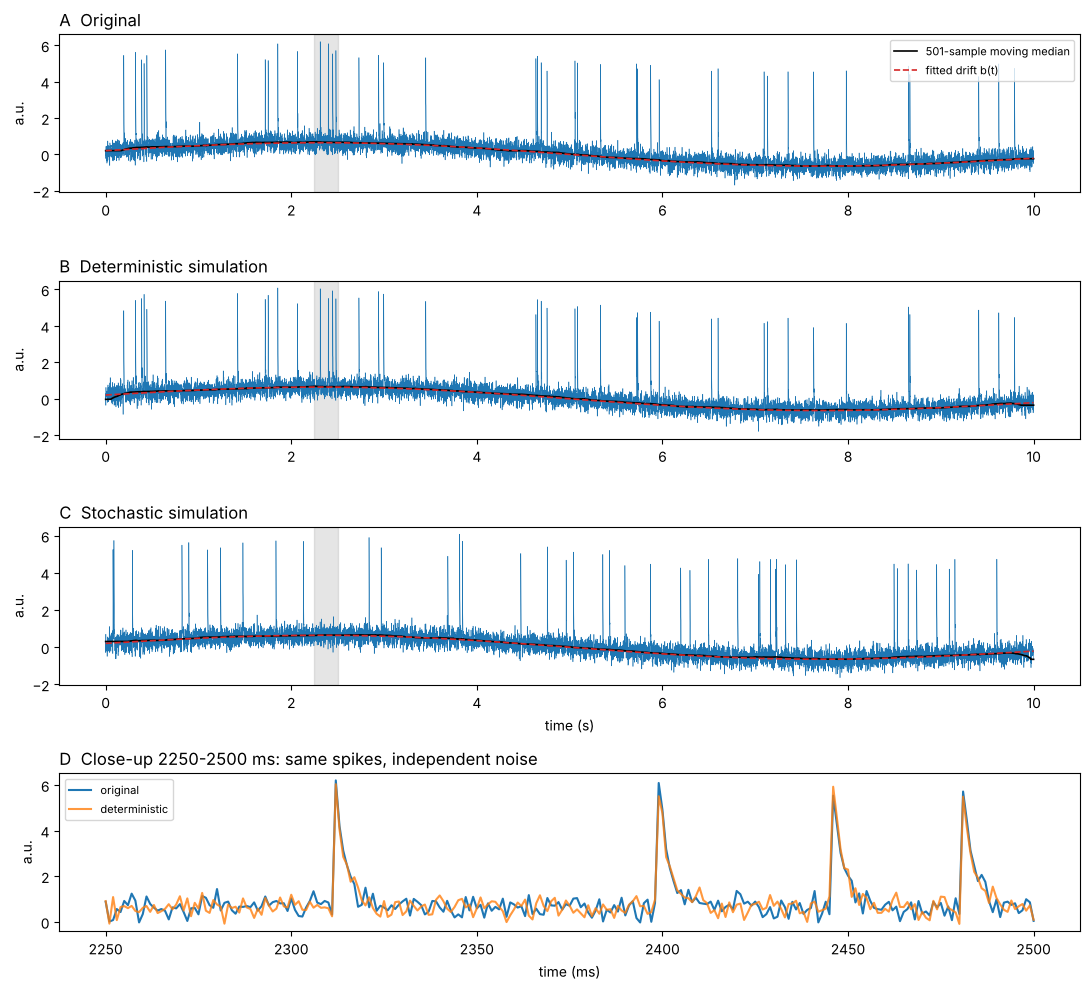

In [16]:
drift_orig = median_filter(x, size=501, mode="nearest")
fig, axes = plt.subplots(4, 1, figsize=(11, 10))
for ax, (name, sig) in zip(axes[:3], [("A  Original", x),
                                      ("B  Deterministic simulation", x_det),
                                      ("C  Stochastic simulation", x_sto)]):
    ax.plot(t, sig, lw=0.4, color="tab:blue")
    ax.plot(t, median_filter(sig, size=501, mode="nearest"), color="black",
            lw=1.2, label="501-sample moving median")
    ax.plot(t, drift, "--", color="tab:red", lw=1.2, label="fitted drift b(t)")
    ax.axvspan(2.25, 2.5, color="grey", alpha=0.2)
    ax.set_title(name, loc="left")
    ax.set_ylabel("a.u.")
axes[0].legend(loc="upper right", fontsize=8)
zoom = (t >= 2.25) & (t <= 2.5)
axes[3].plot(t[zoom] * 1000, x[zoom], label="original")
axes[3].plot(t[zoom] * 1000, x_det[zoom], label="deterministic", alpha=0.8)
axes[3].set_title("D  Close-up 2250-2500 ms: same spikes, independent noise",
                  loc="left")
axes[3].set_xlabel("time (ms)")
axes[3].set_ylabel("a.u.")
axes[3].legend(fontsize=8)
axes[2].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

### Figure 2 — Average spike waveform

Waveform RMSE vs original (deterministic): 0.066 a.u.
Waveform RMSE vs original (stochastic): 0.056 a.u.


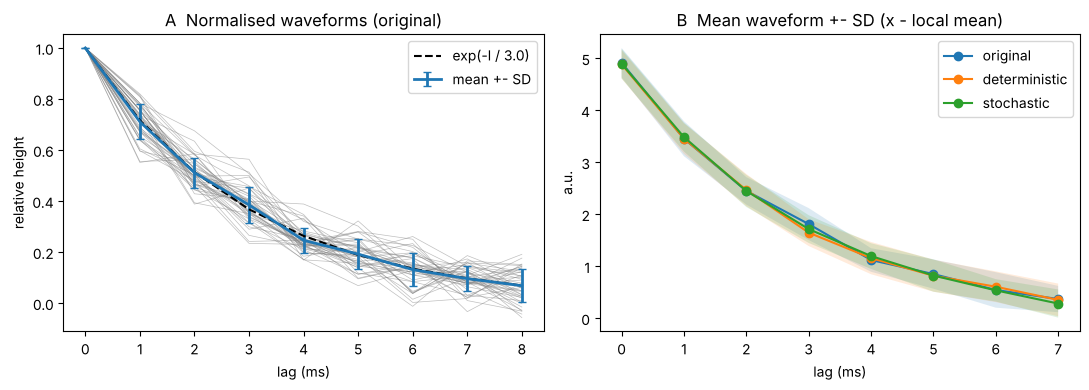

In [17]:
lags = np.arange(9)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# A: drift-free waveforms of the original, each normalised to its peak
normalised = segments / segments[:, :1]
for row in normalised:
    axes[0].plot(lags, row, color="grey", lw=0.5, alpha=0.5)
axes[0].errorbar(lags, normalised.mean(axis=0), normalised.std(axis=0),
                 color="tab:blue", lw=2, capsize=3, label="mean +- SD")
axes[0].plot(lags, np.exp(-lags / tau), "--", color="black",
             label="exp(-l / %.1f)" % tau)
axes[0].set(title="A  Normalised waveforms (original)",
            xlabel="lag (ms)", ylabel="relative height")
axes[0].legend()

# B: mean waveform +- SD exactly as the testing module measures it
for name, sig in [("original", x), ("deterministic", x_det),
                  ("stochastic", x_sto)]:
    waves = tm.features(sig)["waves"]
    m, s = waves.mean(axis=0), waves.std(axis=0)
    axes[1].plot(tm.WAVE, m, marker="o", label=name)
    axes[1].fill_between(tm.WAVE, m - s, m + s, alpha=0.15)
axes[1].set(title="B  Mean waveform +- SD (x - local mean)",
            xlabel="lag (ms)", ylabel="a.u.")
axes[1].legend()
plt.tight_layout()
plt.show()

for name, sig in [("deterministic", x_det), ("stochastic", x_sto)]:
    print("Waveform RMSE vs original (%s): %.3f a.u." %
          (name, tm.rms(tm.mean_wave(tm.features(sig)) - tm.mean_wave(ref))))

### Figure 3 — Residual noise and spectrum

Noise KS distance (deterministic vs original): 0.015
Noise SD: original 0.303, deterministic 0.306


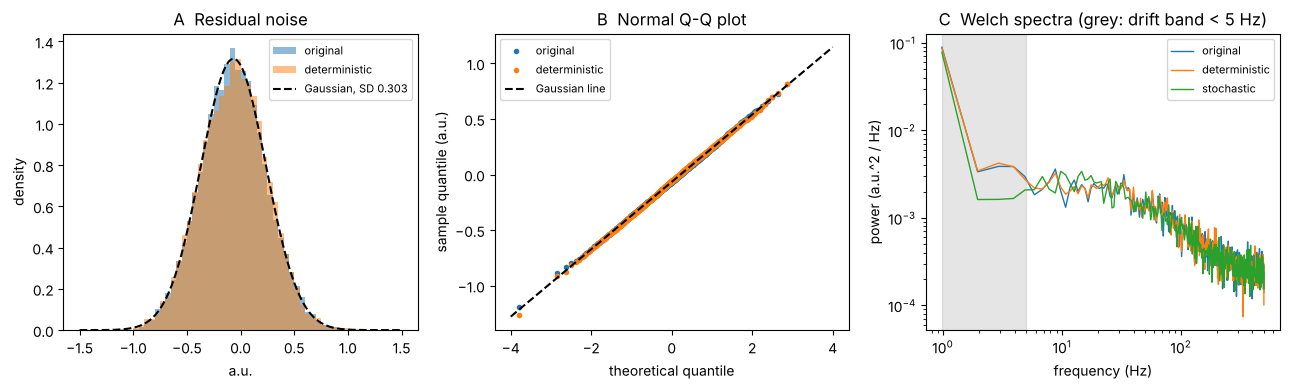

In [18]:
noise_orig = ref["noise"]
noise_det = tm.features(x_det)["noise"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# A: histograms with a Gaussian fit
bins = np.linspace(-1.5, 1.5, 61)
axes[0].hist(noise_orig, bins, density=True, alpha=0.5, label="original")
axes[0].hist(noise_det, bins, density=True, alpha=0.5, label="deterministic")
grid = np.linspace(-1.5, 1.5, 200)
axes[0].plot(grid, stats.norm.pdf(grid, noise_orig.mean(), noise_orig.std()),
             "k--",
             label="Gaussian, SD %.3f" % noise_orig.std())
axes[0].set(title="A  Residual noise", xlabel="a.u.", ylabel="density")
axes[0].legend(fontsize=8)

# B: normal Q-Q plot (every 20th point)
for name, values in [("original", noise_orig), ("deterministic", noise_det)]:
    (theory, ordered), _ = stats.probplot(values, dist="norm")
    axes[1].plot(theory[::20], ordered[::20], ".", label=name)
zz = np.array([-4, 4])
axes[1].plot(zz, noise_orig.mean() + zz * noise_orig.std(), "k--",
             label="Gaussian line")
axes[1].set(title="B  Normal Q-Q plot", xlabel="theoretical quantile",
            ylabel="sample quantile (a.u.)")
axes[1].legend(fontsize=8)

# C: Welch power spectra
for name, sig in [("original", x), ("deterministic", x_det),
                  ("stochastic", x_sto)]:
    freqs, psd = signal.welch(sig - sig.mean(), fs=FS, nperseg=1024,
                              detrend=False)
    axes[2].loglog(freqs[1:], psd[1:], lw=1, label=name)
axes[2].axvspan(freqs[1], 5, color="grey", alpha=0.2)
axes[2].set(title="C  Welch spectra (grey: drift band < 5 Hz)",
            xlabel="frequency (Hz)", ylabel="power (a.u.^2 / Hz)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Noise KS distance (deterministic vs original): %.3f" %
      tm.ks(noise_det, noise_orig))
print("Noise SD: original %.3f, deterministic %.3f" %
      (noise_orig.std(), noise_det.std()))

### Figure 4 — Sensitivity plateau, $k \in [3.0, 6.5]$

original      plateau of 42 spikes: k = 4.3 - 5.4
deterministic plateau of 42 spikes: k = 4.0 - 5.4
stochastic    plateau of 42 spikes: k = 3.5 - 5.2


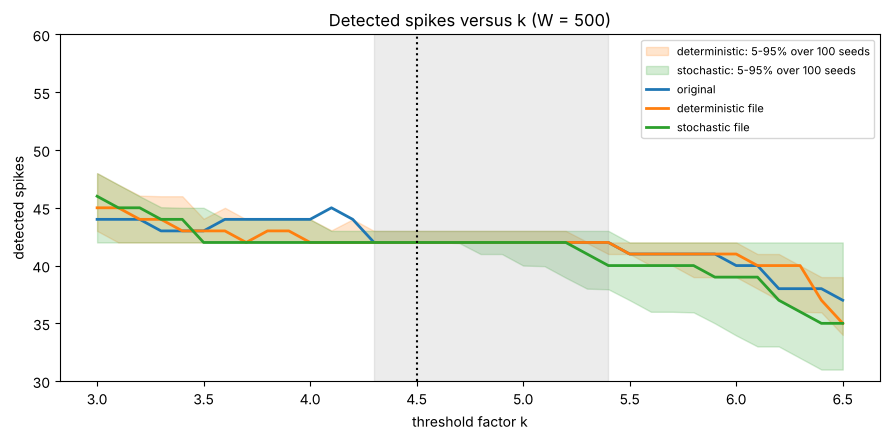

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for mode, color in [("deterministic", "tab:orange"),
                    ("stochastic", "tab:green")]:
    sweeps = np.array(seed_sweeps[mode])
    ax.fill_between(K_VALUES, np.percentile(sweeps, 5, axis=0),
                    np.percentile(sweeps, 95, axis=0), color=color,
                    alpha=0.2, label=mode + ": 5-95% over 100 seeds")
for name, sig, color in [("original", x, "tab:blue"),
                         ("deterministic file", x_det, "tab:orange"),
                         ("stochastic file", x_sto, "tab:green")]:
    ax.plot(K_VALUES, k_sweep(sig), color=color, lw=2, label=name)

def plateau(sig):
    # Widest run of k values around k = 4.5 that all give 42 spikes.
    counts_k = k_sweep(sig)
    centre = int(np.argmin(np.abs(K_VALUES - 4.5)))
    lo, hi = centre, centre
    while lo > 0 and counts_k[lo - 1] == 42:
        lo -= 1
    while hi < len(K_VALUES) - 1 and counts_k[hi + 1] == 42:
        hi += 1
    return K_VALUES[lo], K_VALUES[hi]


k_lo, k_hi = plateau(x)
ax.axvspan(k_lo, k_hi, color="grey", alpha=0.15)
ax.axvline(4.5, ls=":", color="black")
ax.set(xlabel="threshold factor k", ylabel="detected spikes",
       title="Detected spikes versus k (W = 500)", ylim=(30, 60))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, sig in [("original", x), ("deterministic", x_det),
                  ("stochastic", x_sto)]:
    print("%-13s plateau of 42 spikes: k = %.1f - %.1f" % ((name,)
                                                           + plateau(sig)))

### 3c. Does the module rank correctly? Control candidates

Each control has one deliberate change. A good testing module must rank both correct models above every wrong one, must not reward smoothing, and must flag copies. (Controls that use random numbers have fixed seeds.)

In [20]:
os.makedirs("controls", exist_ok=True)
rng = np.random.default_rng(7)


def model_signal(drift_part, amp, tau_ms, noise_sd, times, seed=2026):
    # The fitted model with one or more parts changed.
    noise_rng = np.random.default_rng(seed)
    return (drift_part + amp * spike_train(N, times, tau_ms)
            + noise_rng.normal(0.0, noise_sd, N))


no_trend = drift_columns(t) @ [a, 0.0]
controls = {
    "Copy of the original": x,
    "Original + new noise N(0, 0.05^2)": x + rng.normal(0, 0.05, N),
    "Deterministic file (submission)": x_det,
    "Spike times shifted by +1 ms":
        model_signal(drift, A, tau, sigma, spike_times + 1),
    "Original + new noise N(0, 0.1^2)": x + rng.normal(0, 0.1, N),
    "Stochastic file": x_sto,
    "Drift without linear trend":
        model_signal(no_trend, A, tau, sigma, spike_times),
    "Spike amplitude x 0.7":
        model_signal(drift, 0.7 * A, tau, sigma, spike_times),
    "Spike decay tau = 1.5 ms":
        model_signal(drift, A, 1.5, sigma, spike_times),
    "No drift": model_signal(0.0, A, tau, sigma, spike_times),
    "Noise SD x 1.5": model_signal(drift, A, tau, 1.5 * sigma, spike_times),
    "Noise-free model (drift + spikes)": drift + A * spikes_unit,
    "Double firing rate (84 spikes)":
        model_signal(drift, A, tau, sigma, random_spike_times(N, 84, rng)),
    "No spikes": model_signal(drift, 0.0, tau, sigma, spike_times),
    "Shuffled original": rng.permutation(x),
    "White noise (mean, SD of original)": rng.normal(x.mean(), x.std(), N),
}

control_reports = {}
for i, (name, sig) in enumerate(controls.items()):
    path = "controls/control_%02d.npz" % i
    np.savez(path, t=t, raw_data=sig)
    control_reports[name] = tm.evaluate(path, DATA_FILE, ref)

# One file with the wrong structure: saved as float32 -> repaired, x 0.9
np.savez("controls/control_float32.npz", t=t, raw_data=x_det.astype(np.float32))
control_reports["Deterministic file saved as float32"] = tm.evaluate(
    "controls/control_float32.npz", DATA_FILE, ref)

ranked = sorted(control_reports.items(), key=lambda item: -item[1]["composite"])
print("%-38s %6s %6s %6s %6s %6s %6s  %s" %
      ("Candidate", "T1", "T2", "T3", "T4", "Score", "Stats", "Flag"))
for name, rep in ranked:
    tiers = rep.get("tiers")
    tier_text = (" ".join("%6.1f" % (100 * tiers[k]) for k in tm.TIERS)
                 if tiers else " ".join("%6s" % "-" for k in tm.TIERS))
    flag = "; ".join(rep["notes"])
    print("%-38s %s %6.1f %6.1f  %s" % (name, tier_text, rep["composite"],
                                        rep["statistics_only"], flag))

Candidate                                  T1     T2     T3     T4  Score  Stats  Flag
Copy of the original                    100.0  100.0  100.0  100.0  100.0  100.0  noise correlates with the original noise (r = 1.00): copied?
Original + new noise N(0, 0.05^2)       100.0  100.0  100.0  100.0  100.0  100.0  noise correlates with the original noise (r = 0.99): copied?
Deterministic file (submission)         100.0  100.0  100.0  100.0  100.0  100.0  
Spike times shifted by +1 ms             89.2  100.0  100.0  100.0   97.3  100.0  
Original + new noise N(0, 0.1^2)        100.0   74.9  100.0  100.0   93.7   93.7  noise correlates with the original noise (r = 0.95): copied?
Deterministic file saved as float32     100.0  100.0  100.0  100.0   90.0   90.0  structure differs from spike_data.npz: score x 0.90 after repairs
Stochastic file                          77.6  100.0   98.8   75.6   88.0   99.7  
Drift without linear trend               63.2  100.0   66.9  100.0   82.5   73.8  
Spik

### Figure 5 — Scores of the control candidates

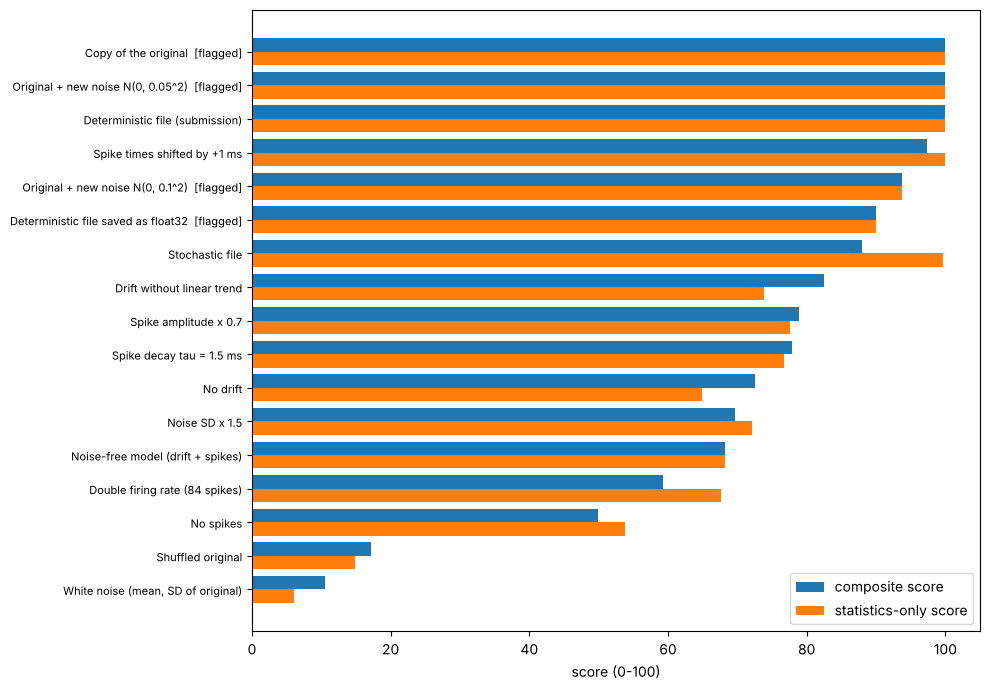

In [21]:
names = [name for name, _ in ranked][::-1]
total = [control_reports[n]["composite"] for n in names]
stats_only = [control_reports[n]["statistics_only"] for n in names]
positions = np.arange(len(names))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(positions + 0.2, total, height=0.4, label="composite score")
ax.barh(positions - 0.2, stats_only, height=0.4, label="statistics-only score")
labels = [n + ("  [flagged]" if control_reports[n]["notes"] else "")
          for n in names]
ax.set_yticks(positions)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("score (0-100)")
ax.set_xlim(0, 105)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Part 4 — Score other teams' files

Put the other teams' files (`.npz`, `.npy`, `.csv`, `.txt` or `.mat`) in the Colab **Files** panel (or upload them with the cell below by setting `UPLOAD_OTHER_TEAMS = True`), then list their names in `OTHER_TEAM_FILES`. With an empty list, this cell only ranks my own two files, so **Run all** never stops here.

In [22]:
UPLOAD_OTHER_TEAMS = False        # set to True to get an upload box
OTHER_TEAM_FILES = []             # e.g. ["team_A.npz", "team_B.npz"]

if UPLOAD_OTHER_TEAMS:
    from google.colab import files
    OTHER_TEAM_FILES += list(files.upload().keys())

candidates = ["simulated_spike_data.npz",
              "simulated_spike_data_stochastic.npz"] + OTHER_TEAM_FILES
results = []
for path in candidates:
    if not os.path.exists(path):
        print("Not found, skipped:", path)
        continue
    results.append((path, tm.evaluate(path, DATA_FILE, ref)))

print("=== Ranking ===")
results.sort(key=lambda item: -item[1]["composite"])
for rank, (path, rep) in enumerate(results, start=1):
    flag = ("  [" + "; ".join(rep["notes"]) + "]") if rep["notes"] else ""
    print("%2d. %5.1f  (statistics-only %5.1f)  %s%s" %
          (rank, rep["composite"], rep["statistics_only"], path, flag))

=== Ranking ===
 1. 100.0  (statistics-only 100.0)  simulated_spike_data.npz
 2.  88.0  (statistics-only  99.7)  simulated_spike_data_stochastic.npz


# Summary

* **Model.** Drift $b(t) = 0.535\sin(2\pi t/10\,\text{s}) - 0.042\,(t-5\,\text{s})$; 42 spikes of $A = 5.01$ a.u. with an exponential decay of $\tau = 3.0$ ms; white Gaussian noise with $\sigma = 0.2985$ a.u. Tail rebounds, the spread of spike heights and the peak at sample 1014 are all explained by noise.
* **Results file.** `simulated_spike_data.npz` has exactly the structure of the original and scores 100 / 100 (all errors at chance level, noise not copied).
* **Testing module.** Ten simple metrics in four tiers, each judged against the error that chance alone produces. It ranks correct models above wrong ones, does not reward smoothing (noise-free model), flags copies, and repairs files with a different structure (missing `t`, other key names, `float32`, ...) but scores them × 0.9; only files with no usable signal get 0.
* **Limitations.** All parameters come from one 10-s recording; correct deterministic reconstructions all tie at 100; differences below ~4 points between stochastic submissions are within chance; the module sees only spikes that the 2B detector finds.

## Download all result files

In [23]:
RESULT_FILES = ["simulated_spike_data.npz",
                "simulated_spike_data_stochastic.npz",
                "model_parameters.json", "testing_module.py"]

with zipfile.ZipFile("reverse_engineering_results.zip", "w") as archive:
    for name in RESULT_FILES:
        archive.write(name)
print("Wrote reverse_engineering_results.zip with:", RESULT_FILES)

try:
    from google.colab import files
    files.download("reverse_engineering_results.zip")
except ImportError:
    print("(Not in Colab: the ZIP is in the notebook's folder.)")

Wrote reverse_engineering_results.zip with: ['simulated_spike_data.npz', 'simulated_spike_data_stochastic.npz', 'model_parameters.json', 'testing_module.py']
(Not in Colab: the ZIP is in the notebook's folder.)
